# Customer Segmentation and Sales EDA (Python)

**Goal:** understand sales patterns in a retail dataset and segment customers with **RFM analysis** (Recency, Frequency, Monetary) plus **K-Means**, so marketing can treat each group differently.

> **Data note:** the data is **synthetic** (generated by `generate_data.py`, seeded), so it contains no real customer information. The notebook shows the method. Findings describe this dataset, not a real business.

**Steps:** 1) load and validate data, 2) exploratory analysis, 3) RFM scoring and rule-based segments, 4) K-Means clustering check, 5) insights and recommendations.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

## 1. Load and validate the data

In [2]:
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])
products  = pd.read_csv("data/products.csv")
orders    = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
items     = pd.read_csv("data/order_items.csv")

for name, df in [("customers", customers), ("products", products), ("orders", orders), ("order_items", items)]:
    print(f"{name:12s} rows={len(df):6d}  nulls={int(df.isna().sum().sum())}  duplicate_rows={int(df.duplicated().sum())}")

# referential integrity: every order has a customer, every item has an order and a product
print("orders without customer:", (~orders.customer_id.isin(customers.customer_id)).sum())
print("items without order    :", (~items.order_id.isin(orders.order_id)).sum())
print("items without product  :", (~items.product_id.isin(products.product_id)).sum())

customers    rows=  3000  nulls=0  duplicate_rows=0
products     rows=    60  nulls=0  duplicate_rows=0
orders       rows=  9000  nulls=0  duplicate_rows=0
order_items  rows= 17071  nulls=0  duplicate_rows=0
orders without customer: 0
items without order    : 0
items without product  : 0


In [3]:
# one flat table at line-item level
df = (items.merge(orders, on="order_id")
           .merge(products, on="product_id")
           .merge(customers, on="customer_id"))
df["revenue"] = df.quantity * df.unit_price * (1 - df.discount)
df["profit"]  = df.revenue - df.quantity * df.unit_cost
print(df.shape)
df[["order_id", "order_date", "region", "segment", "category", "quantity", "discount", "revenue", "profit"]].head()

(17071, 19)


,order_id,order_date,region,segment,category,quantity,discount,revenue,profit
0,1,2024-03-29,South,Corporate,Furniture,1,0.20,417.87,96.54
1,1,2024-03-29,South,Corporate,Electronics,2,0.20,"1,046.82",47.78
2,1,2024-03-29,South,Corporate,Furniture,3,0.20,993.14,-60.34
3,2,2024-07-14,East,Consumer,Electronics,2,0.00,"1,092.52",362.64
4,3,2025-02-27,West,Home Office,Office Supplies,1,0.10,4.46,0.73


## 2. Exploratory analysis

In [4]:
total_rev, total_profit = df.revenue.sum(), df.profit.sum()
n_orders = df.order_id.nunique()
print(f"Revenue {total_rev:,.0f} | Profit {total_profit:,.0f} ({total_profit/total_rev:.1%}) | "
      f"Orders {n_orders:,} | Avg order value {total_rev/n_orders:,.2f} | Active customers {df.customer_id.nunique():,}")

Revenue 7,772,870 | Profit 2,200,233 (28.3%) | Orders 9,000 | Avg order value 863.65 | Active customers 2,682


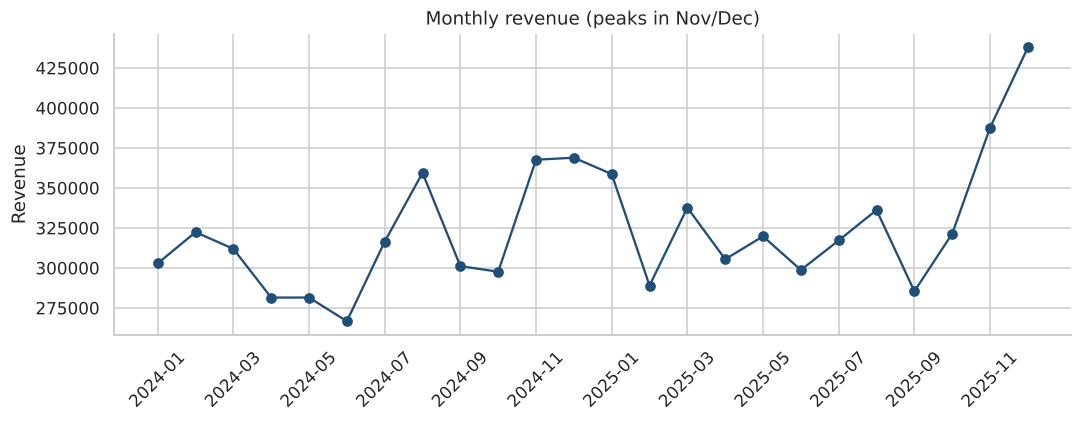

{2024: 3.78, 2025: 3.99} -> growth 5.7%
Nov+Dec share of revenue: 20.1% (an even spread would be 16.7%)
Electronics share of revenue: 64.9%


In [5]:
monthly = df.groupby(df.order_date.dt.to_period("M")).revenue.sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", color="#1f4e79")
ax.set_title("Monthly revenue (peaks in Nov/Dec)")
ax.set_ylabel("Revenue")
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels(monthly.index.astype(str)[::2], rotation=45)
plt.tight_layout(); plt.savefig("figures/01_monthly_revenue.png"); plt.show()

yearly = df.groupby(df.order_date.dt.year).revenue.sum()
print((yearly / 1e6).round(2).to_dict(), f"-> growth {yearly.iloc[1]/yearly.iloc[0]-1:.1%}")
nov_dec = df[df.order_date.dt.month.isin([11, 12])].revenue.sum() / total_rev
print(f"Nov+Dec share of revenue: {nov_dec:.1%} (an even spread would be 16.7%)")
print(f"Electronics share of revenue: {df[df.category=='Electronics'].revenue.sum()/total_rev:.1%}")

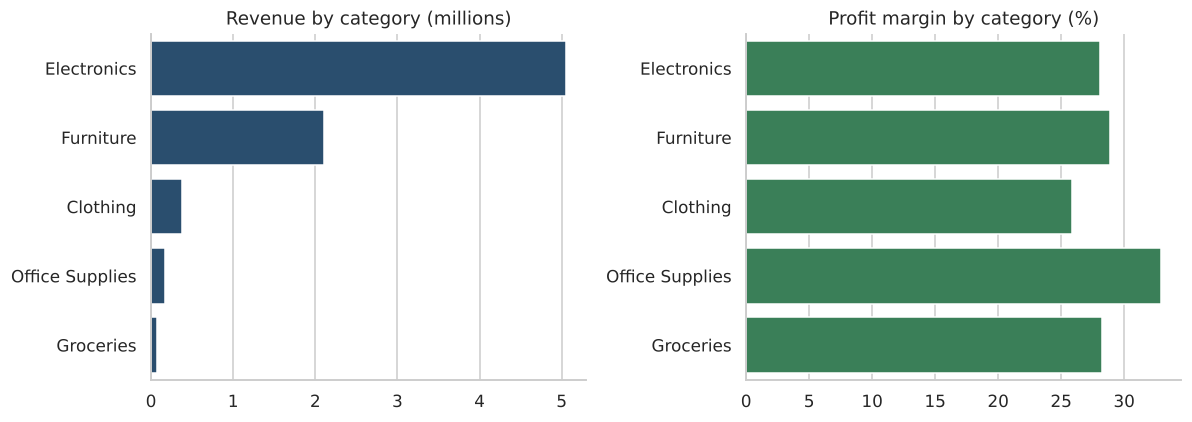

,revenue,profit,units,margin_pct
category,,,,
Electronics,"5,047,680.50","1,418,461.70",7921,28.10
Furniture,"2,102,570.20","607,410.30",5933,28.90
Clothing,"382,223.70","98,727.40",5189,25.80
Office Supplies,"166,397.10","54,740.10",6790,32.90
Groceries,"73,998.40","20,893.30",4810,28.20


In [6]:
cat = df.groupby("category").agg(revenue=("revenue", "sum"), profit=("profit", "sum"), units=("quantity", "sum"))
cat["margin_pct"] = cat.profit / cat.revenue * 100
cat = cat.sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=cat.revenue / 1e6, y=cat.index, ax=axes[0], color="#1f4e79")
axes[0].set_title("Revenue by category (millions)"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
sns.barplot(x=cat.margin_pct, y=cat.index, ax=axes[1], color="#2e8b57")
axes[1].set_title("Profit margin by category (%)"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("figures/02_category.png"); plt.show()
cat.round(1)

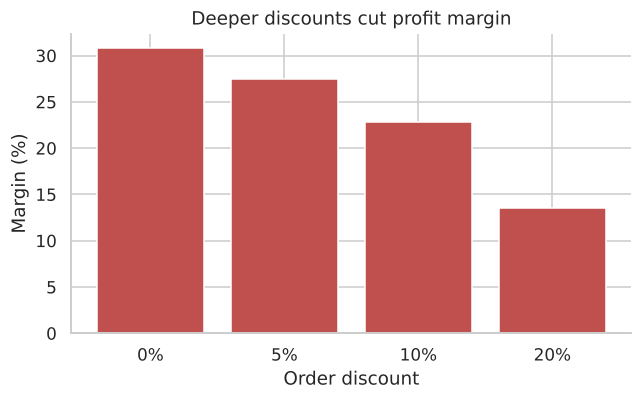

,revenue,profit,margin_pct
discount,,,
0.00,"4,781,517.10","1,473,930.40",30.80
0.05,"1,626,551.90","446,115.70",27.40
0.10,"1,026,296.30","234,431.80",22.80
0.20,"338,504.60","45,754.90",13.50


In [7]:
disc = df.groupby("discount").agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
disc["margin_pct"] = disc.profit / disc.revenue * 100
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar((disc.index * 100).astype(int).astype(str) + "%", disc.margin_pct, color="#c0504d")
ax.set_title("Deeper discounts cut profit margin"); ax.set_xlabel("Order discount"); ax.set_ylabel("Margin (%)")
plt.tight_layout(); plt.savefig("figures/03_discount_margin.png"); plt.show()
disc.round(1)

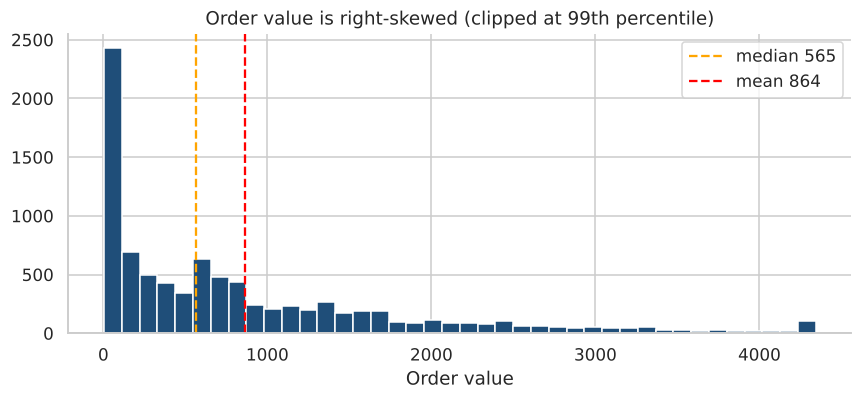

In [8]:
order_value = df.groupby("order_id").revenue.sum()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(order_value.clip(upper=order_value.quantile(0.99)), bins=40, color="#1f4e79")
ax.axvline(order_value.median(), color="orange", ls="--", label=f"median {order_value.median():,.0f}")
ax.axvline(order_value.mean(), color="red", ls="--", label=f"mean {order_value.mean():,.0f}")
ax.set_title("Order value is right-skewed (clipped at 99th percentile)"); ax.set_xlabel("Order value"); ax.legend()
plt.tight_layout(); plt.savefig("figures/04_order_value.png"); plt.show()

## 3. RFM analysis

For every customer:
- **Recency:** days since last order (lower is better), measured from a snapshot date one day after the last order in the data
- **Frequency:** number of orders
- **Monetary:** total revenue

Each is scored 1 to 5 using quintiles, and customers are grouped into named segments using simple business rules.

In [9]:
snapshot = df.order_date.max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_id").agg(
    recency=("order_date", lambda s: (snapshot - s.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("revenue", "sum"),
)
print(rfm.describe().round(1))

       recency  frequency  monetary
count 2,682.00   2,682.00  2,682.00
mean    201.80       3.40  2,898.20
std     181.00       3.00  3,188.20
min       1.00       1.00      4.10
25%      52.00       2.00    811.50
50%     145.50       3.00  1,964.50
75%     313.00       4.00  3,958.80
max     729.00      69.00 48,617.00


In [10]:
# quintile scores; rank(method="first") avoids duplicate-edge errors on ties (many customers have 1 or 2 orders)
rfm["R"] = pd.qcut(rfm.recency.rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)   # recent = high score
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def label(r):
    if r.R >= 4 and r.F >= 4 and r.M >= 4: return "Champions"
    if r.F >= 4 and r.M >= 3:               return "Loyal"
    if r.R >= 4 and r.F <= 2:               return "New / Promising"
    if r.R <= 2 and r.F >= 4:               return "At Risk"
    if r.R <= 2 and r.F <= 2:               return "Lost / Hibernating"
    return "Needs Attention"

rfm["segment"] = rfm.apply(label, axis=1)
seg = rfm.groupby("segment").agg(customers=("monetary", "size"), avg_recency=("recency", "mean"),
                                 avg_orders=("frequency", "mean"), avg_spend=("monetary", "mean"),
                                 revenue=("monetary", "sum"))
seg["pct_customers"] = seg.customers / seg.customers.sum() * 100
seg["pct_revenue"] = seg.revenue / seg.revenue.sum() * 100
seg = seg.sort_values("revenue", ascending=False)
seg.round(1)

,customers,avg_recency,avg_orders,avg_spend,revenue,pct_customers,pct_revenue
segment,,,,,,,
Champions,462,40.40,7.10,"6,913.30","3,193,961.50",17.20,41.10
Loyal,475,184.80,4.60,"3,973.50","1,887,432.50",17.70,24.30
Needs Attention,803,163.10,2.60,"1,980.10","1,589,983.30",29.90,20.50
Lost / Hibernating,664,422.80,1.40,"1,095.80","727,642.70",24.80,9.40
New / Promising,240,46.50,1.60,"1,394.40","334,664.00",8.90,4.30
At Risk,38,315.50,3.80,"1,031.20","39,185.80",1.40,0.50


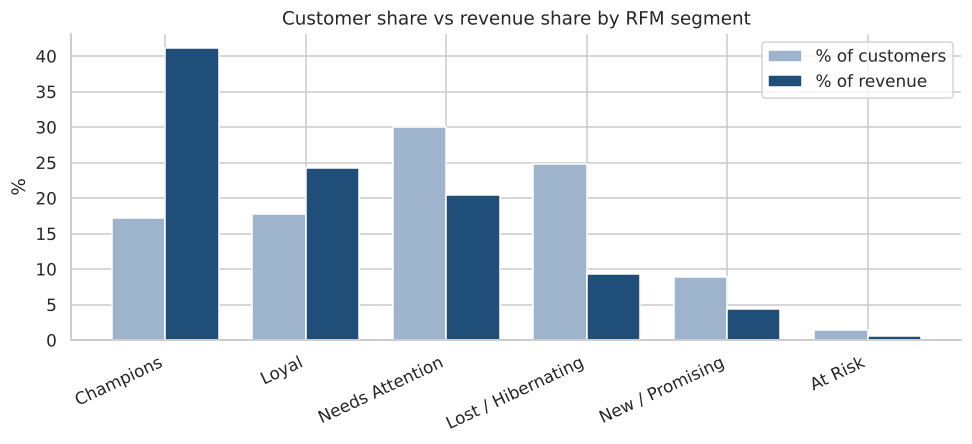

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(seg)); w = 0.38
ax.bar(x - w/2, seg.pct_customers, w, label="% of customers", color="#9db4cc")
ax.bar(x + w/2, seg.pct_revenue, w, label="% of revenue", color="#1f4e79")
ax.set_xticks(x); ax.set_xticklabels(seg.index, rotation=25, ha="right")
ax.set_ylabel("%"); ax.set_title("Customer share vs revenue share by RFM segment"); ax.legend()
plt.tight_layout(); plt.savefig("figures/05_rfm_segments.png"); plt.show()

## 4. K-Means check

Rule-based segments are easy to explain. As a sanity check, cluster the same customers with K-Means on log-scaled, standardised R, F, M, and compare. The silhouette score is used as a guide for the number of clusters, alongside how useful the groups are in practice.

In [12]:
X = StandardScaler().fit_transform(np.log1p(rfm[["recency", "frequency", "monetary"]]))
scores = {}
for k in range(2, 8):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels)
print({k: round(v, 3) for k, v in scores.items()})
print("highest silhouette: k =", max(scores, key=scores.get))
# k=2 only separates active from lapsed customers. k=4 scores almost as well and gives groups marketing can act on.
best_k = 4
print("using k =", best_k, "| silhouette", round(scores[best_k], 3))

{2: 0.35, 3: 0.316, 4: 0.328, 5: 0.316, 6: 0.275, 7: 0.286}
highest silhouette: k = 2
using k = 4 | silhouette 0.328


In [13]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_
prof = rfm.groupby("cluster").agg(customers=("monetary", "size"), recency=("recency", "mean"),
                                  frequency=("frequency", "mean"), monetary=("monetary", "mean"))
prof["pct_revenue"] = rfm.groupby("cluster").monetary.sum() / rfm.monetary.sum() * 100
prof.round(1)

,customers,recency,frequency,monetary,pct_revenue
cluster,,,,,
0,366,342.50,1.30,133.30,0.60
1,1174,291.10,2.30,"2,044.80",30.90
2,500,29.60,3.00,"2,503.10",16.10
3,642,92.60,6.80,"6,342.60",52.40


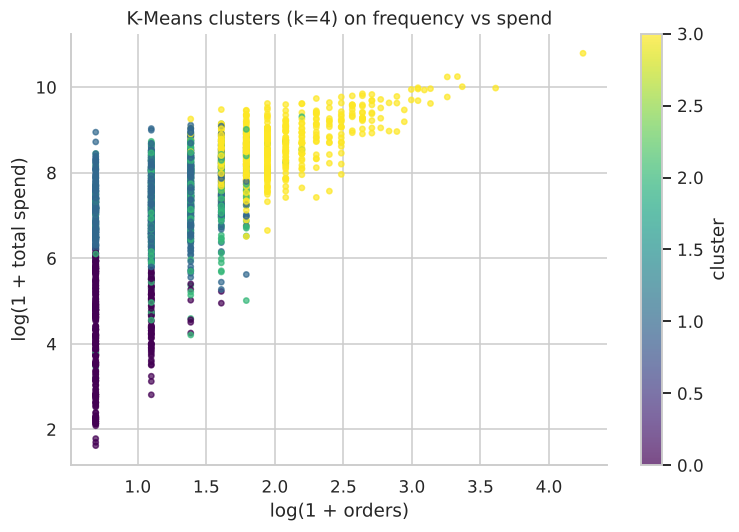

cluster               0    1    2    3
segment                               
At Risk               1   37    0    0
Champions             0    0   96  366
Lost / Hibernating  240  424    0    0
Loyal                 0  161   49  265
Needs Attention      76  496  220   11
New / Promising      49   56  135    0


In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(np.log1p(rfm.frequency), np.log1p(rfm.monetary), c=rfm.cluster, cmap="viridis", s=12, alpha=0.7)
ax.set_xlabel("log(1 + orders)"); ax.set_ylabel("log(1 + total spend)")
ax.set_title(f"K-Means clusters (k={best_k}) on frequency vs spend")
plt.colorbar(sc, label="cluster"); plt.tight_layout(); plt.savefig("figures/06_kmeans.png"); plt.show()

print(pd.crosstab(rfm.segment, rfm.cluster))

In [15]:
rfm.reset_index().to_csv("rfm_segments.csv", index=False)
print("saved rfm_segments.csv with", len(rfm), "customers")

saved rfm_segments.csv with 2682 customers


## 5. Insights and recommendations

**What the data shows**
1. **Growth and seasonality:** revenue grew 5.7% from 2024 to 2025, and November and December carry about a fifth of annual revenue.
2. **Product mix:** Electronics alone is about 65% of revenue. Office Supplies has the best margin (32.9%) but is tiny in revenue terms.
3. **Discounts hurt profitability:** margin falls from 30.8% with no discount to 13.5% at a 20% discount.
4. **Revenue is concentrated in a few customers:** Champions are 17.2% of customers but 41.1% of revenue. Champions plus Loyal are 34.9% of customers and 65.4% of revenue.
5. **A large lapsed group:** Lost / Hibernating customers are 24.8% of customers but only 9.4% of revenue, and last ordered about 423 days before the snapshot on average.
6. **K-Means agrees with the rules.** With k = 4 the clusters are:
   - *Cluster 3, loyal high spenders:* 642 customers (about 24%), 6.8 orders each, 52.4% of revenue
   - *Cluster 2, recent mid-value:* 500 customers, last order about 30 days ago, 16.1% of revenue
   - *Cluster 1, lapsing mid-value:* 1,174 customers (about 44%), last order about 291 days ago, 30.9% of revenue
   - *Cluster 0, lapsed low-value:* 366 customers, about 1.3 orders each, 0.6% of revenue

**Suggested actions (illustrative)**
- **Champions and Loyal:** protect with early access and loyalty rewards, not discounts. They already buy at full price.
- **Cluster 1 (lapsing mid-value):** the biggest recoverable pool. Run a targeted win-back campaign before they drift into the lapsed group.
- **New / Promising (240 customers):** send a follow-up offer after the first purchase to get a second order, since repeat buyers are worth far more.
- **Discount policy:** limit the 20% tier, because it earns less than half the full-price margin.

**Limitations**
- The data is synthetic, so the specific numbers are not evidence about any real business.
- RFM quintile scores are relative to this customer base, not absolute thresholds.
- Returns, acquisition cost and customer lifetime beyond the observed 2 years are not modelled.
- K-Means with k = 2 had the highest silhouette score (0.35). k = 4 (0.33) was chosen because it gives more actionable groups.
